In [1]:
# Import the pandas library and give it the short nickname "pd"
# pandas is the main Python tool for working with tables of data
import pandas as pd

# Read the CSV file into a DataFrame (a table) and store it in a variable called df
df = pd.read_csv(
    "Sample - Superstore.csv",              # the file name (must be in the same folder as your notebook)
    encoding="latin1",                      # tells pandas how to read special characters; the default (utf-8) fails on this file
    parse_dates=["Order Date", "Ship Date"] # convert these two columns from plain text into real dates
)

# Show the number of rows and columns as (rows, columns)
df.shape

# Show each column's name, data type, and how many non-empty values it has
# Use this to spot missing data and columns stored as the wrong type
df.info()

# Show the first 5 rows so you can see what the data actually looks like
df.head()

# Show summary statistics (count, mean, min, max, quartiles) for the numeric columns
# Use this to spot odd values, like negative profit or very large sales
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355648,2016-05-03 23:06:58.571142912,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108


In [2]:
# Count missing (empty) values in every column
# Any number above 0 means that column has gaps we'd need to deal with
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [3]:
# Count rows that are exact duplicates of another row
# Duplicates would double-count sales, so we need to know about them
df.duplicated().sum()

np.int64(0)

In [4]:
# Count how many unique values each column has
# Useful for spotting ID columns, and columns with only one value (which are useless for analysis)
df.nunique()

Row ID           9994
Order ID         5009
Order Date       1237
Ship Date        1334
Ship Mode           4
Customer ID       793
Customer Name     793
Segment             3
Country             1
City              531
State              49
Postal Code       631
Region              4
Product ID       1862
Category            3
Sub-Category       17
Product Name     1850
Sales            5825
Quantity           14
Discount           12
Profit           7287
dtype: int64

In [5]:
# Check the date range covered by the data
# This tells us how many years we can compare for growth
print(df["Order Date"].min())   # earliest order
print(df["Order Date"].max())   # latest order

2014-01-03 00:00:00
2017-12-30 00:00:00


In [6]:
# Drop the "Row ID" column, which is just a row counter and carries no information
# axis=1 means "drop a column" (axis=0 would mean drop a row)
df = df.drop("Row ID", axis=1)

In [8]:
# Now re-check for duplicate rows, since Row ID was hiding any copies before
df.duplicated().sum()

np.int64(1)

In [9]:
# Create a "Year" column by pulling the year out of each order date
# .dt gives access to date parts (year, month, day, etc.)
df["Year"] = df["Order Date"].dt.year

# Create a "Month" column (1 = January, 12 = December) for seasonal analysis
df["Month"] = df["Order Date"].dt.month

# Create a "Profit Margin" column: what share of each sale is profit
# e.g. 0.25 means 25p of every £1 in sales is profit; negative means a loss
df["Profit Margin"] = df["Profit"] / df["Sales"]

# Show the first 5 rows to confirm the new columns appear correctly
df.head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Profit Margin
0,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,0.1600
1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,0.3000
2,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,0.4700
3,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,-0.4000
4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,0.1125


In [10]:
# Calculate the headline numbers for the whole business
total_sales = df["Sales"].sum()            # total revenue across all orders
total_profit = df["Profit"].sum()          # total profit across all orders
num_orders = df["Order ID"].nunique()      # number of unique orders (not rows!)

# Print each result; :,.0f adds thousand separators and rounds to whole numbers
print(f"Total sales:   {total_sales:,.0f}")
print(f"Total profit:  {total_profit:,.0f}")
print(f"Overall margin: {total_profit / total_sales:.1%}")   # :.1% shows a percentage to 1 decimal place
print(f"Orders:        {num_orders:,}")

Total sales:   2,297,201
Total profit:  286,397
Overall margin: 12.5%
Orders:        5,009


In [11]:
# Show the duplicated row(s) so we can see what they are before deleting
# keep=False marks BOTH copies, so we see the original and the duplicate side by side
df[df.duplicated(keep=False)]

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Profit Margin
3405,US-2014-150119,2014-04-23,2014-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,...,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588,2014,4,-0.042857
3406,US-2014-150119,2014-04-23,2014-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,...,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588,2014,4,-0.042857


In [12]:
# Remove the duplicate row, keeping the first copy
df = df.drop_duplicates()

# Drop the Country column (Row ID is already gone)
df = df.drop("Country", axis=1)

# Confirm: should now be 9,993 rows and 0 duplicates
print(df.shape)
print(df.duplicated().sum())

(9993, 22)
0


In [13]:
# Group the data by year and add up sales and profit for each year
# .agg() lets us apply a different calculation to each column
yearly = df.groupby("Year").agg(
    Sales=("Sales", "sum"),            # total sales per year
    Profit=("Profit", "sum"),          # total profit per year
    Orders=("Order ID", "nunique")     # number of unique orders per year
)

# Add profit margin for each year
yearly["Margin"] = yearly["Profit"] / yearly["Sales"]

# Add year-on-year sales growth: % change compared with the previous year
# .pct_change() compares each row with the one above it (the first year shows NaN, as there's nothing to compare it to)
yearly["Sales Growth"] = yearly["Sales"].pct_change()

# Round to 2 decimal places to make the table easier to read
yearly.round(2)

,Sales,Profit,Orders,Margin,Sales Growth
Year,,,,,
2014,483966.13,49556.03,969,0.10,NaN
2015,470532.51,61618.60,1038,0.13,-0.03
2016,609205.60,81795.17,1315,0.13,0.29
2017,733215.26,93439.27,1687,0.13,0.20


In [14]:
# Calculate average order value (AOV) per year: total sales divided by number of orders
yearly["AOV"] = yearly["Sales"] / yearly["Orders"]

# Show the table again with the new column
yearly.round(2)

,Sales,Profit,Orders,Margin,Sales Growth,AOV
Year,,,,,,
2014,483966.13,49556.03,969,0.10,NaN,499.45
2015,470532.51,61618.60,1038,0.13,-0.03,453.31
2016,609205.60,81795.17,1315,0.13,0.29,463.27
2017,733215.26,93439.27,1687,0.13,0.20,434.63


In [15]:
# Group by Region and total up sales and profit, then add margin
region = df.groupby("Region").agg(
    Sales=("Sales", "sum"),      # total sales per region
    Profit=("Profit", "sum")     # total profit per region
)
region["Margin"] = region["Profit"] / region["Sales"]   # profit as a share of sales

# Sort from highest to lowest profit so the best region is at the top
region.sort_values("Profit", ascending=False).round(2)

,Sales,Profit,Margin
Region,,,
West,725457.82,108418.45,0.15
East,678499.87,91534.84,0.13
South,391721.90,46749.43,0.12
Central,501239.89,39706.36,0.08


In [16]:
# Same again, but grouped by Category AND Sub-Category
# Grouping by two columns gives one row per sub-category within each category
subcat = df.groupby(["Category", "Sub-Category"]).agg(
    Sales=("Sales", "sum"),            # total sales per sub-category
    Profit=("Profit", "sum"),          # total profit per sub-category
    Avg_Discount=("Discount", "mean")  # average discount given on that sub-category
)
subcat["Margin"] = subcat["Profit"] / subcat["Sales"]   # profit as a share of sales

# Sort by profit, lowest first, so the loss-makers appear at the top
subcat.sort_values("Profit").round(2)

Sales    Profit  Avg_Discount  Margin
Category        Sub-Category                                           
Furniture       Tables        206965.53 -17725.48          0.26   -0.09
                Bookcases     114880.00  -3472.56          0.21   -0.03
Office Supplies Supplies       46673.54  -1189.10          0.08   -0.03
                Fasteners       3024.28    949.52          0.08    0.31
Technology      Machines      189238.63   3384.76          0.31    0.02
Office Supplies Labels         12486.31   5546.25          0.07    0.44
                Art            27118.79   6527.79          0.07    0.24
                Envelopes      16476.40   6964.18          0.08    0.42
Furniture       Furnishings    91705.16  13059.14          0.14    0.14
Office Supplies Appliances    107532.16  18138.01          0.17    0.17
                Storage       223843.61  21278.83          0.07    0.10
Furniture       Chairs        328167.73  26602.23          0.17    0.08
Office Supplies Binders       203412.73  30221.76          0.37    0.15
                Paper          78479.21  34053.57          0.07    0.43
Technology      Accessories   167380.32  41936.64          0.08    0.25
                Phones        330007.05  44515.73          0.15    0.13
                Copiers       149528.03  55617.82          0.16    0.37

In [17]:
# Put each row's discount into a band (bin) so we can compare groups
# bins are the edges of each band; labels are the names shown for each band
df["Discount Band"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.2, 0.4, 0.8],                   # -0.01 so that 0% discounts fall in the first band
    labels=["No discount", "1-20%", "21-40%", "41-80%"]
)

# For each discount band: count of lines, total sales, total profit
bands = df.groupby("Discount Band", observed=True).agg(   # observed=True only shows bands that exist in the data
    Lines=("Sales", "count"),     # number of order lines in each band
    Sales=("Sales", "sum"),       # total sales in each band
    Profit=("Profit", "sum")      # total profit in each band
)
bands["Margin"] = bands["Profit"] / bands["Sales"]   # profit as a share of sales

bands.round(2)

,Lines,Sales,Profit,Margin
Discount Band,,,,
No discount,4798,1087908.47,320987.60,0.30
1-20%,3803,846522.24,100785.47,0.12
21-40%,459,233856.53,-35805.41,-0.15
41-80%,933,128632.25,-99558.59,-0.77


In [18]:
# Does Central give bigger discounts than the other regions?
# Average discount and share of lines discounted above 20%, per region
df.groupby("Region").agg(
    Avg_Discount=("Discount", "mean"),                        # average discount per region
    Share_Over_20=("Discount", lambda x: (x > 0.2).mean())    # fraction of lines with more than 20% off
).round(2)

,Avg_Discount,Share_Over_20
Region,,
Central,0.24,0.28
East,0.15,0.16
South,0.15,0.11
West,0.11,0.04


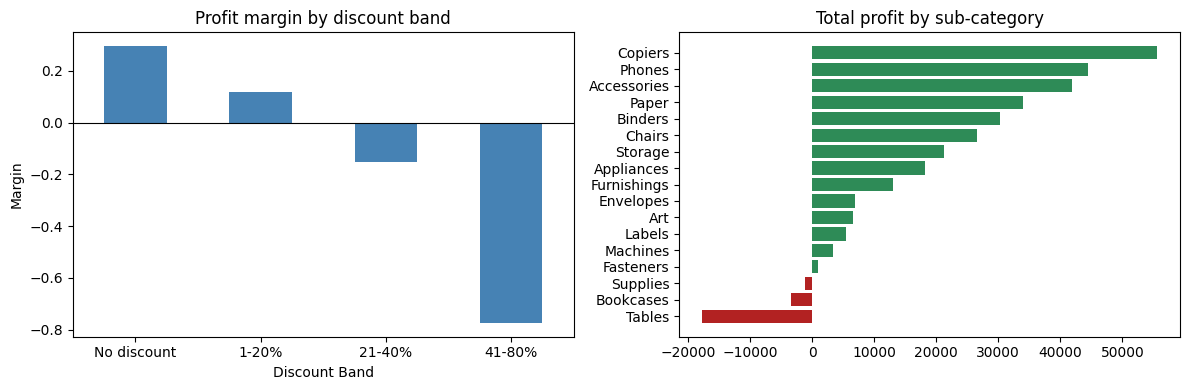

In [19]:
# Import matplotlib, Python's main plotting library; "plt" is the standard nickname
import matplotlib.pyplot as plt

# Create a figure with 2 charts side by side; figsize is (width, height) in inches
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Chart 1: profit margin by discount band, as a bar chart on the left (axes[0])
bands["Margin"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].axhline(0, color="black", linewidth=0.8)    # horizontal line at 0 to show where losses start
axes[0].set_title("Profit margin by discount band") # chart title
axes[0].set_ylabel("Margin")                        # y-axis label
axes[0].tick_params(axis="x", rotation=0)           # keep x-axis labels horizontal

# Chart 2: profit by sub-category, as a horizontal bar chart on the right (axes[1])
subcat_sorted = subcat.reset_index().sort_values("Profit")    # turn the grouped index back into columns, sort by profit
colors = ["firebrick" if p < 0 else "seagreen" for p in subcat_sorted["Profit"]]   # red for losses, green for profit
axes[1].barh(subcat_sorted["Sub-Category"], subcat_sorted["Profit"], color=colors) # barh = horizontal bars
axes[1].set_title("Total profit by sub-category")             # chart title

plt.tight_layout()   # stop the two charts' labels from overlapping
plt.show()           # display the charts

In [20]:
# Save the cleaned data as a new CSV for Power BI
# index=False stops pandas writing its row numbers as an extra column
df.to_csv("superstore_clean.csv", index=False)

In [21]:
# Keep only rows for Tables and Bookcases
# .isin() checks whether each value is in the list given
furn = df[df["Sub-Category"].isin(["Tables", "Bookcases"])]

# For each sub-category and discount band: number of lines, total sales, total profit
result = furn.groupby(["Sub-Category", "Discount Band"], observed=True).agg(
    Lines=("Sales", "count"),     # number of order lines
    Sales=("Sales", "sum"),       # total sales
    Profit=("Profit", "sum")      # total profit
)
result["Margin"] = result["Profit"] / result["Sales"]   # profit as a share of sales

result.round(2)

Lines     Sales    Profit  Margin
Sub-Category Discount Band                                   
Bookcases    No discount       60  31935.98   6075.71    0.19
             1-20%             98  54400.02   1549.49    0.03
             21-40%            37  18776.16  -2947.01   -0.16
             41-80%            33   9767.84  -8150.75   -0.83
Tables       No discount       72  71578.76  13276.30    0.19
             1-20%             71  45430.23   -303.56   -0.01
             21-40%           129  70796.56 -19589.72   -0.28
             41-80%            47  19159.98 -11108.50   -0.58

In [22]:
# Build a grid: one row per sub-category, one column per region
# Each cell shows the average discount for that sub-category in that region
pd.pivot_table(
    df,
    index="Sub-Category",   # rows: one per sub-category
    columns="Region",       # columns: one per region
    values="Discount",      # the value to calculate
    aggfunc="mean"          # use the average
).round(2)                  # round to 2 decimal places

Region,Central,East,South,West
Sub-Category,,,,
Accessories,0.12,0.09,0.09,0.04
Appliances,0.45,0.07,0.11,0.03
Art,0.12,0.07,0.10,0.03
Binders,0.51,0.35,0.38,0.28
Bookcases,0.23,0.22,0.10,0.23
Chairs,0.19,0.15,0.10,0.20
Copiers,0.11,0.25,0.09,0.14
Envelopes,0.13,0.08,0.07,0.04
Fasteners,0.13,0.09,0.08,0.03


In [26]:
# 1. Summary: Cap discounts at 20% company-wide (about half of profit is lost above that level).
# 2. Stop discounting tables; trial in one region first (19% margin at full price).
# 3. Bring Central’s discounting in line with West’s and investigate the cause (up to ~35k extra profit).

In [27]:
# List every column name in the DataFrame, to confirm "Order Date" exists
print(df.columns.tolist())

# Read back the saved CSV and list its columns, to confirm it was saved correctly
print(pd.read_csv("superstore_clean.csv").columns.tolist())

['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Year', 'Month', 'Profit Margin', 'Discount Band']
['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Year', 'Month', 'Profit Margin', 'Discount Band']
